# WR properties

This notebook uses the optical depth calculation to determine what stars are in a WR phase.

## setup/preamble

In [3]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm

# custom helper scripts
from helper_functions import calc_Teff

# Solar metallicity


Load the data and combine S1 and S2 into a single population

In [1]:
data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicity = 1.0
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [88]:
# hydrogen-poor/free stars

WR_types = []
time_array = []
weight_array = []
state_array = []
key_array = []
star_array = []  # Track whether entry is from S1 or S2
period_array = []
separation_array = []
Teff_array = []
L_array = []
optical_depth_array = []
surface_H_array = []
surface_He_array = []
mass_array = []
radius_array = []
Mdot_array = []
companion_array = []

for key in tqdm(S1_WR_data):
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    optical_depth = S1_WR_data[key]['optical_depth']
    
    surface_H = data['S1_surface_h1']
    surface_He = data['S1_surface_he4']
    Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
    
    # WR classification
    WN_mask = (surface_H <= 0.4) & (optical_depth >= 1.5)
    WC_mask = (surface_H <= 0.4) & (surface_He < 0.7) & (optical_depth >= 1.5)
    
    WR_types.extend(np.where(WC_mask, 'WC', np.where(WN_mask, 'WN', 'stripped-He')))
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S1'] * len(data))  # Mark as S1
    Teff_array.extend(Teff)
    L_array.extend(10**data['S1_log_L'].values)
    optical_depth_array.extend(optical_depth)
    surface_H_array.extend(surface_H.values)
    surface_He_array.extend(surface_He.values)
    mass_array.extend(data['S1_mass'].values)
    radius_array.extend(10**data['S1_log_R'].values)
    Mdot_array.extend(10**data['S1_lg_mdot'].values)
    companion_array.extend(data['S2_state'].values)
    
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S1_mass'].values,
                                         data['S2_mass'].values)
    
    separation_array.extend(sep)
    
    
for key in tqdm(S2_WR_data):
    data = S2_WR_data[key]['data']
    weights = S2_WR_data[key]['weights']
    optical_depth = S2_WR_data[key]['optical_depth']
    
    surface_H = data['S2_surface_h1']
    surface_He = data['S2_surface_he4']
    Teff = 10**calc_Teff(data['S2_log_L'], data['S2_log_R'])
    
    # WR classification
    WN_mask = (surface_H <= 0.4) & (optical_depth >= 1.5)
    WC_mask = (surface_H <= 0.4) & (surface_He < 0.7) & (optical_depth >= 1.5)
    
    WR_types.extend(np.where(WC_mask, 'WC', np.where(WN_mask, 'WN', 'stripped-He')))
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S2'] * len(data))  # Mark as S2
    Teff_array.extend(Teff)
    L_array.extend(10**data['S2_log_L'].values)
    optical_depth_array.extend(optical_depth)
    surface_H_array.extend(surface_H.values)
    surface_He_array.extend(surface_He.values)
    mass_array.extend(data['S2_mass'].values)
    radius_array.extend(10**data['S2_log_R'].values)
    Mdot_array.extend(10**data['S2_lg_mdot'].values)
    companion_array.extend(data['S1_state'])
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S2_mass'].values,
                                         data['S1_mass'].values)
    
    separation_array.extend(sep)
    

WR_types = np.array(WR_types)
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
star_array = np.array(star_array)  # Convert to array
period_array = np.array(period_array)
separation_array = np.array(separation_array)
Teff_array = np.array(Teff_array)
L_array = np.array(L_array)
optical_depth_array = np.array(optical_depth_array)
surface_H_array = np.array(surface_H_array)
surface_He_array = np.array(surface_He_array)
mass_array = np.array(mass_array)
radius_array = np.array(radius_array)
Mdot_array = np.array(Mdot_array)
companion_array = np.array(companion_array)

100%|██████████| 38190/38190 [00:24<00:00, 1557.97it/s]


## HR diagram

An HR diagram to make sure we're looking at the correct systems.

In [89]:
WN_mask = WR_types == 'WN'
WC_mask = WR_types == 'WC'
stripped_He_mask = WR_types == 'stripped-He'

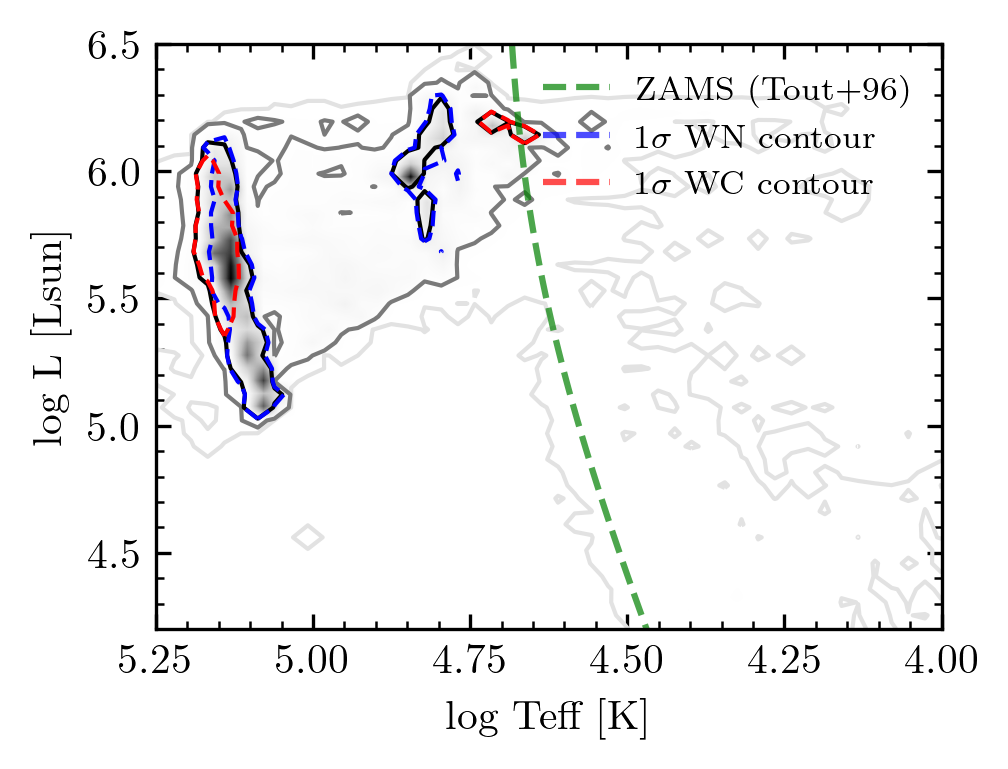

In [90]:
from helper_functions import tout_L_ZAMS, tout_R_ZAMS
# 2d histogram of Teff and L

cm_grays = Colormap('colorbrewer:Greys')

T_bins = np.linspace(4.0, 5.3, 51)
L_bins = np.linspace(4.0, 6.5, 51)

(H0, xedges, yedges) = \
        np.histogram2d(np.log10(Teff_array)[WN_mask | WC_mask],
                       np.log10(L_array)[WN_mask | WC_mask],
                       weights=weight_array[WN_mask | WC_mask],
                       bins=[T_bins, L_bins])


H0 /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
H0_sorted = np.sort(H0.flatten())[::-1]
H0_cumsum = H0_sorted.cumsum()
H0_total = H0_cumsum[-1]
# Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)
level0_1 = H0_sorted[np.searchsorted(H0_cumsum, 0.683 * H0_total)]
level0_2 = H0_sorted[np.searchsorted(H0_cumsum, 0.954 * H0_total)]
level0_3 = H0_sorted[np.searchsorted(H0_cumsum, 0.997 * H0_total)]
levels0 = [level0_3, level0_2, level0_1]

plt.imshow(H0.T,
            origin='lower',
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            cmap=cm_grays.to_mpl(),
            aspect='auto',
            interpolation='bilinear')

plt.contour(H0.T,
            levels=levels0,
            colors=cm_grays([0.2, 0.6, 1.0]),
            linewidths=[1.0, 1.0, 1.0],
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])


# plot WN and WC contours
H_WN, _, _ = \
        np.histogram2d(np.log10(Teff_array)[WN_mask],
                       np.log10(L_array)[WN_mask],
                       weights=weight_array[WN_mask],
                       bins=[T_bins, L_bins])
H_WN /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
H_WN_sorted = np.sort(H_WN.flatten())[::-1]
H_WN_cumsum = H_WN_sorted.cumsum()
H_WN_total = H_WN_cumsum[-1]
# Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)
level_WN_3 = H_WN_sorted[np.searchsorted(H_WN_cumsum, 0.683 * H_WN_total)]
levels_WN = [level_WN_3]

plt.contour(H_WN.T,
            levels=levels_WN,
            colors='blue',
            linewidths=[1.0],
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            linestyles='dashed',)

H_WC, _, _ = \
        np.histogram2d(np.log10(Teff_array)[WC_mask],
                       np.log10(L_array)[WC_mask],
                       weights=weight_array[WC_mask],
                       bins=[T_bins, L_bins])
H_WC /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
H_WC_sorted = np.sort(H_WC.flatten())[::-1]
H_WC_cumsum = H_WC_sorted.cumsum()
H_WC_total = H_WC_cumsum[-1]
# Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)

level_WC_3 = H_WC_sorted[np.searchsorted(H_WC_cumsum, 0.683 * H_WC_total)]
levels_WC = [level_WC_3]
plt.contour(H_WC.T,
            levels=levels_WC,
            colors='red',
            linewidths=[1.0],
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            linestyles='dashed',)


# Add ZAMS and HeMS lines
# ZAMS from Hurley et al. (2000, MNRAS, 315, 543)
# Using their fitting formulas for solar metallicity
# For M in range ~1-120 Msun, compute ZAMS L and Teff
M_zams = np.logspace(0.7, 2.5, 100) 

L_zams = tout_L_ZAMS(M_zams)
R_zams = tout_R_ZAMS(M_zams)

# Hurley et al. (2000) for ZAMS Teff (derived from their radius formula)
# log(Teff) approximation for MS stars
log_Teff_zams = calc_Teff(np.log10(L_zams), np.log10(R_zams))
log_L_zams = np.log10(L_zams)

plt.plot(log_Teff_zams, log_L_zams, 'g--', linewidth=1.5, label='ZAMS (Tout+96)', alpha=0.7)
plt.plot([], [], 'b--', linewidth=1.5, label='$1\sigma$ WN contour', alpha=0.7)
plt.plot([], [], 'r--', linewidth=1.5, label='$1\sigma$ WC contour', alpha=0.7)
plt.xlim(5.25, 4.0)
plt.ylim(4.2, 6.5)
plt.xlabel('log Teff [K]')
plt.ylabel('log L [Lsun]')
plt.legend(loc='upper right')

plt.show()


## Binary fraction per sub-type

Should I sub-define these further?

There's a very high binary fraction for the helium stars. T

In [91]:
# binary fraction per WR type
print(np.unique(state_array))
# remove ERR, initial_RLO

# MT binaries don't really matter
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')

WN_mask = WR_types == 'WN'
WC_mask = WR_types == 'WC'
stripped_He_mask = WR_types == 'stripped-He'

WR_binary_fraction = np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]) / np.sum(weight_array[(binary_mask | single_star_mask) & (WN_mask | WC_mask)])

print("WR binary fraction:", WR_binary_fraction)
print("WN binary fraction:", np.sum(weight_array[binary_mask & WN_mask]) / np.sum(weight_array[(binary_mask | single_star_mask) & WN_mask]))
print("WC binary fraction:", np.sum(weight_array[binary_mask & WC_mask]) / np.sum(weight_array[(binary_mask | single_star_mask) & WC_mask]))

print('binary faction helium stars', np.sum(weight_array[binary_mask])/np.sum(weight_array[(binary_mask | single_star_mask)]))

print("WC/WN ratio:", np.sum(weight_array[binary_mask & WC_mask]) / np.sum(weight_array[binary_mask & WN_mask]))

['ERR' 'RLO1' 'RLO2' 'contact' 'detached' 'disrupted' 'initial_RLOF'
 'merged']
WR binary fraction: 0.743864543863545
WN binary fraction: 0.784403757593278
WC binary fraction: 0.6712535549807136
binary faction helium stars 0.9548550945406433
WC/WN ratio: 0.4777711296908551


## Companion fractions

In [92]:
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')

in_binary_companions = companion_array[binary_mask]

WR_weights = weight_array[WN_mask | WC_mask]


print(np.unique(in_binary_companions))

# BH
bh_mask = companion_array == 'BH'
print('BH:', np.sum(weight_array[(binary_mask & bh_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# NS
ns_mask = companion_array == 'NS'
print('NS:', np.sum(weight_array[(binary_mask & ns_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# WD
wd_mask = companion_array == 'WD'
print('WD:', np.sum(weight_array[(binary_mask & wd_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# stripped star
# 'stripped_He_Core_C_depleted', 'stripped_He_Core_He_burning',
# 'stripped_He_Core_He_depleted', 'stripped_He_non_burning'
ss_mask = np.core.defchararray.find(companion_array, 'stripped') != -1
print('stripped:', np.sum(weight_array[(binary_mask & ss_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

ms_mask = companion_array == 'H-rich_Core_H_burning'
print('MS:', np.sum(weight_array[(binary_mask & ms_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

# Hertzsprung gap
hg_mask = companion_array == 'H-rich_Shell_H_burning'
print('HG:', np.sum(weight_array[(binary_mask & hg_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# giants
g_mask = (companion_array == 'H-rich_Core_He_burning') | (companion_array == 'H-rich_Shell_He_burning') | (companion_array == 'H-rich_He_depleted')
print('giants:', np.sum(weight_array[(binary_mask & g_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

# verification that this is very small:
final = (companion_array == 'H-rich_Core_C_depleted')
print('final:', np.sum(weight_array[(binary_mask & final) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

['BH' 'H-rich_Core_C_depleted' 'H-rich_Core_H_burning'
 'H-rich_Core_He_burning' 'H-rich_Core_He_depleted'
 'H-rich_Shell_H_burning' 'H-rich_non_burning' 'NS' 'WD'
 'accreted_He_Core_H_burning' 'stripped_He_Core_C_depleted'
 'stripped_He_Core_He_burning' 'stripped_He_Core_He_depleted'
 'stripped_He_non_burning']
BH: 0.17761261611963222
NS: 0.0001887590019271832
WD: 0.0
stripped: 0.06614889036334912
MS: 0.73078794819657
HG: 0.01183916927529132
giants: 0.013106719508220314
final: 1.746022199842222e-09


## Period/separation distribution

I want 2 different representations. One where we are just looking at the period distribution, the other how the binary fraction changes.

### Cumulative binary fraction over separation

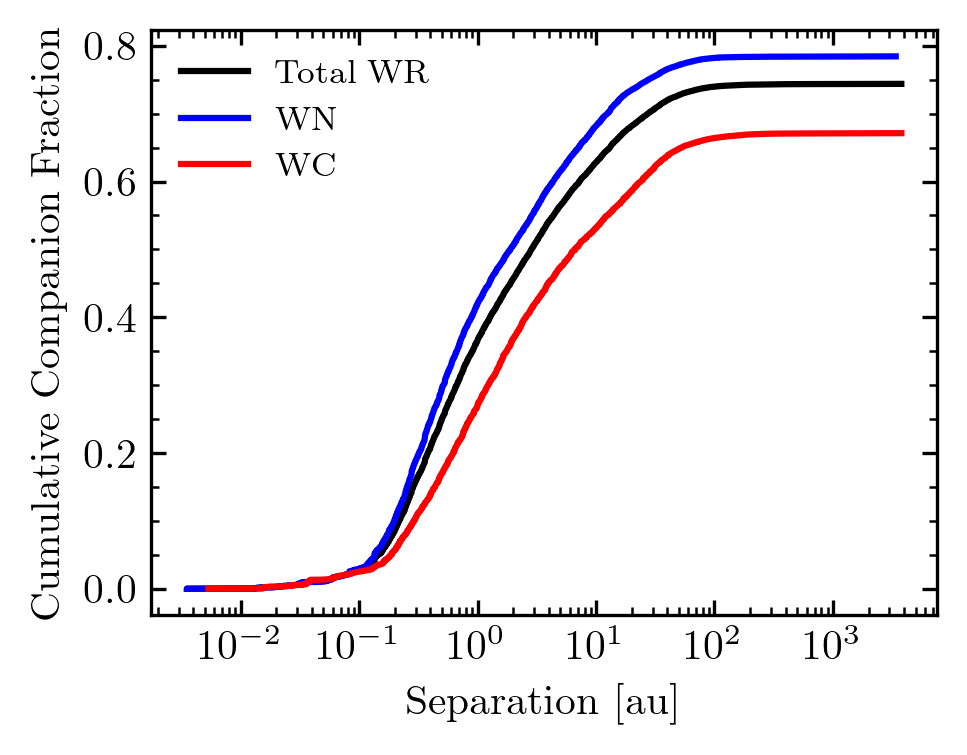

In [93]:
rsun2au = 0.004650476
# Analyze binary fraction among WR phases
# as a function of orbital period
# plot period against, cumulative weight fraction

# all WRs in binaries
sorted_indices = np.argsort(separation_array[binary_mask & (WN_mask | WC_mask)])
sorted_periods = separation_array[binary_mask & (WN_mask | WC_mask)][sorted_indices]
sorted_weights = weight_array[binary_mask & (WN_mask | WC_mask)][sorted_indices]

cumulative_weights = np.cumsum(sorted_weights)
cumulative_weights /= np.sum(weight_array[(WN_mask | WC_mask)])  # normalize to all WRs
plt.plot(sorted_periods * rsun2au, cumulative_weights, color='black', label='Total WR')

# all WN in binaries
sorted_indices = np.argsort(separation_array[binary_mask & WN_mask])
sorted_periods = separation_array[binary_mask & WN_mask][sorted_indices]
sorted_weights = weight_array[binary_mask & WN_mask][sorted_indices]
cumulative_weights = np.cumsum(sorted_weights)
cumulative_weights /= np.sum(weight_array[WN_mask])  # normalize to all WN
plt.plot(sorted_periods * rsun2au, cumulative_weights, color='blue', label='WN')

# all WC in binaries
sorted_indices = np.argsort(separation_array[binary_mask & WC_mask])
sorted_periods = separation_array[binary_mask & WC_mask][sorted_indices]
sorted_weights = weight_array[binary_mask & WC_mask][sorted_indices]
cumulative_weights = np.cumsum(sorted_weights)
cumulative_weights /= np.sum(weight_array[WC_mask])  # normalize to all WC
plt.plot(sorted_periods * rsun2au, cumulative_weights, color='red', label='WC')

plt.xscale('log')
plt.xlabel('Separation [au]')
plt.ylabel('Cumulative Companion Fraction')
plt.legend()
plt.show()

### Period distributions

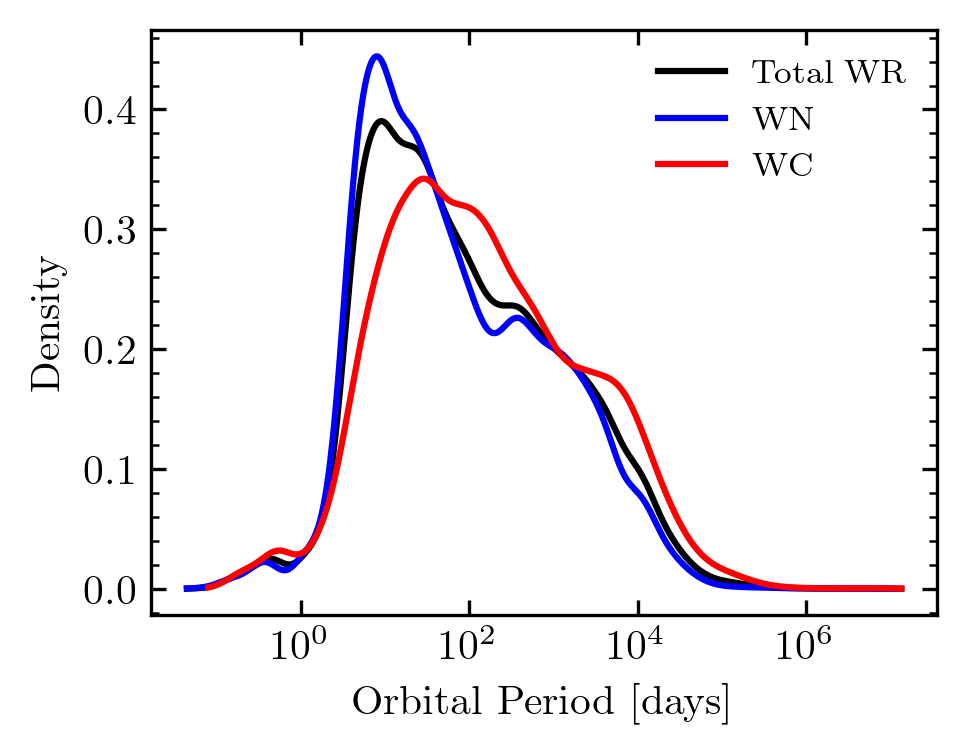

In [94]:
from scipy.stats import gaussian_kde
period_selection = period_array[(binary_mask) & (WN_mask | WC_mask)]

# all WRs in binaries
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WN_mask | WC_mask)])
x_eval = np.linspace(np.log10(np.min(period_selection)), np.log10(np.max(period_selection)), 1000)
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='black', label='Total WR')

# all WN in binaries
period_selection = period_array[(binary_mask) & (WN_mask)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WN_mask)])
x_eval = np.linspace(np.log10(np.min(period_selection)), np.log10(np.max(period_selection)), 1000)
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='blue', label='WN')

# all WC in binaries
period_selection = period_array[(binary_mask) & (WC_mask)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WC_mask)])
x_eval = np.linspace(np.log10(np.min(period_selection)), np.log10(np.max(period_selection)), 1000)
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='red', label='WC')

plt.xscale('log')
plt.xlabel('Orbital Period [days]')
plt.ylabel('Density')
plt.legend()
plt.show()

## Binary interactions

In [95]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2025_11_04/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

Missing ini parameter: metallicity


In [96]:
HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

In [97]:
S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

In [98]:
WR_mask =( WR_types == 'WN' )| (WR_types == 'WC')

# S1 interaction masks - only apply to S1 entries
S1_entries = (star_array == 'S1')
mask_stable = S1_entries & np.isin(key_array, np.array(list(S1_stable_indices)))
mask_unstable = S1_entries & np.isin(key_array, np.array(list(S1_unstable_indices)))
mask_reverse_stable = S1_entries & np.isin(key_array, np.array(list(S1_reverse_stable_indices)))
mask_no_MT = S1_entries & np.isin(key_array, np.array(list(S1_no_MT_indices)))

In [99]:
S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (star_array == 'S2')
S2_mask_stable = S2_entries & np.isin(key_array, np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(key_array, np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(key_array, np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(key_array, np.array(list(S2_no_MT_indices)))

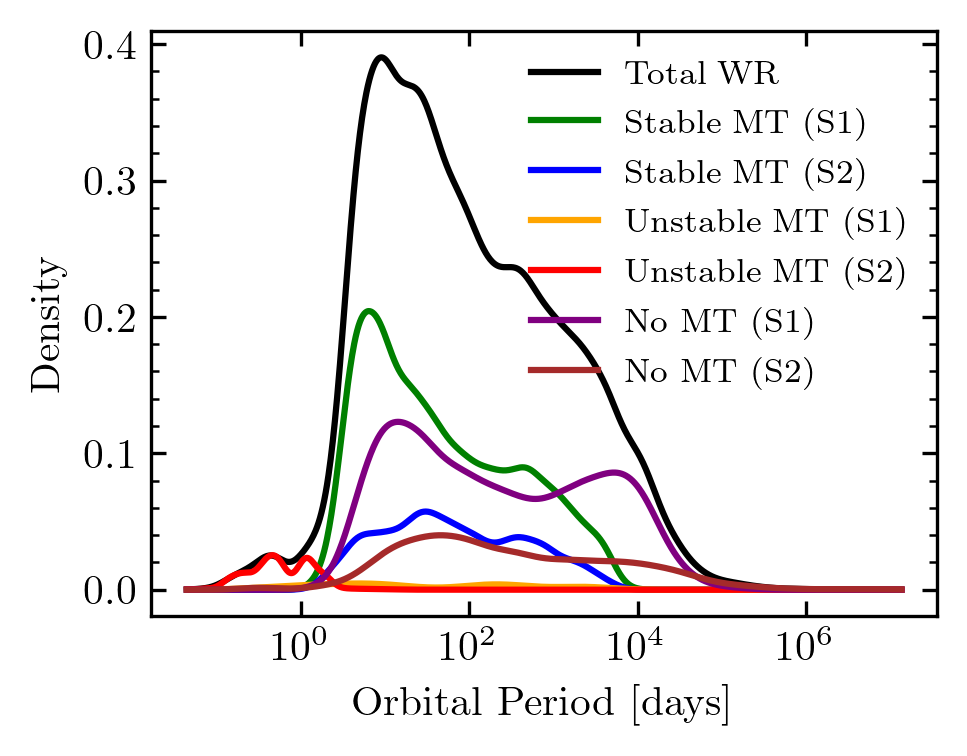

In [104]:
# Define common x_eval range for ALL KDEs
period_selection_all = period_array[(binary_mask) & (WR_mask)]
x_eval = np.linspace(np.log10(np.min(period_selection_all)), np.log10(np.max(period_selection_all)), 1000)

# Total WR distribution (for reference)
period_selection = period_array[(binary_mask) & (WN_mask | WC_mask)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WN_mask | WC_mask)])
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='black', label='Total WR')

# Initialize sum
h = np.zeros_like(x_eval)

# S1 stable MT
period_selection = period_array[(binary_mask) & (WR_mask) & (mask_stable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (mask_stable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (mask_stable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='green', label='Stable MT (S1)')

# S2 stable MT
period_selection = period_array[(binary_mask) & (WR_mask) & (S2_mask_stable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (S2_mask_stable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (S2_mask_stable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='blue', label='Stable MT (S2)')

# unstable MT
period_selection = period_array[(binary_mask) & (WR_mask) & (mask_unstable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (mask_unstable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (mask_unstable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='orange', label='Unstable MT (S1)')

# unstable S2 MT
period_selection = period_array[(binary_mask) & (WR_mask) & (S2_mask_unstable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (S2_mask_unstable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (S2_mask_unstable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='red', label='Unstable MT (S2)')

# no MT
period_selection = period_array[(binary_mask) & (WR_mask) & (mask_no_MT)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (mask_no_MT)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (mask_no_MT)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='purple', label='No MT (S1)')

# no MT S2
period_selection = period_array[(binary_mask) & (WR_mask) & (S2_mask_no_MT)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (S2_mask_no_MT)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (S2_mask_no_MT)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='brown', label='No MT (S2)')

# Plot sum
#plt.plot(10**x_eval, h, 'k--', label='Sum', linewidth=2)

plt.xscale('log')
plt.xlabel('Orbital Period [days]')
plt.ylabel('Density')
plt.legend()
plt.show()

### Non-interacting systems

I want to understand why this population is there.

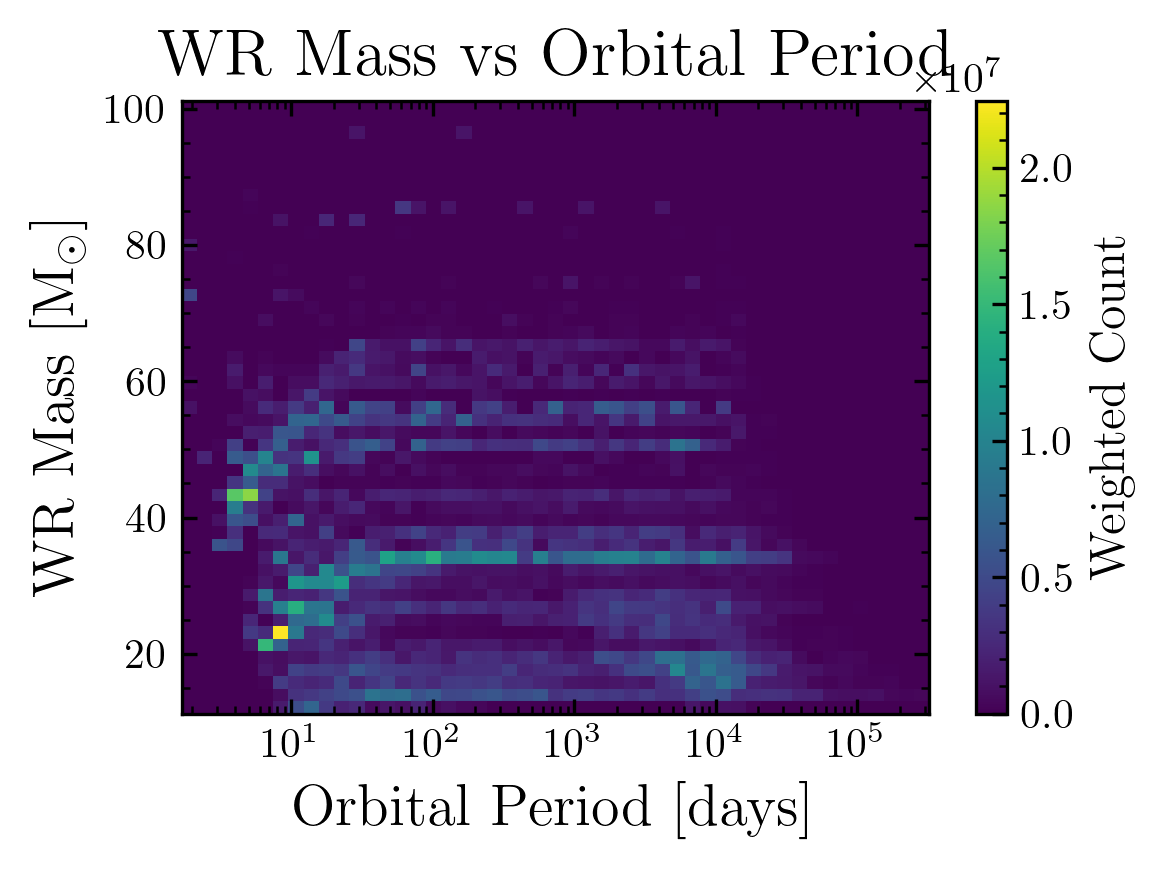

In [157]:
# 2D histogram of WR mass vs orbital period
fig, ax = plt.subplots(figsize=(4, 3))

# Define bins
period_bins = np.logspace(np.log10(np.min(period_array[binary_mask & WR_mask & mask_no_MT])), 
                          np.log10(np.max(period_array[binary_mask & WR_mask & mask_no_MT])), 50)
mass_bins = np.linspace(np.min(mass_array[binary_mask & WR_mask & mask_no_MT]), 
                        np.max(mass_array[binary_mask & WR_mask & mask_no_MT]), 50)

# Create 2D histogram
H, xedges, yedges = np.histogram2d(period_array[binary_mask & WR_mask & mask_no_MT],
                                   mass_array[binary_mask & WR_mask & mask_no_MT],
                                   weights=weight_array[binary_mask & WR_mask & mask_no_MT],
                                   bins=[period_bins, mass_bins])

# Plot
im = ax.pcolormesh(xedges, yedges, H.T, cmap='viridis', shading='auto')
ax.set_xscale('log')
ax.set_xlabel('Orbital Period [days]', fontsize=14)
ax.set_ylabel('WR Mass [M$_\\odot$]', fontsize=14)
ax.set_title('WR Mass vs Orbital Period', fontsize=16)

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Weighted Count', fontsize=12)

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Initial Primary Mass [Msun]')

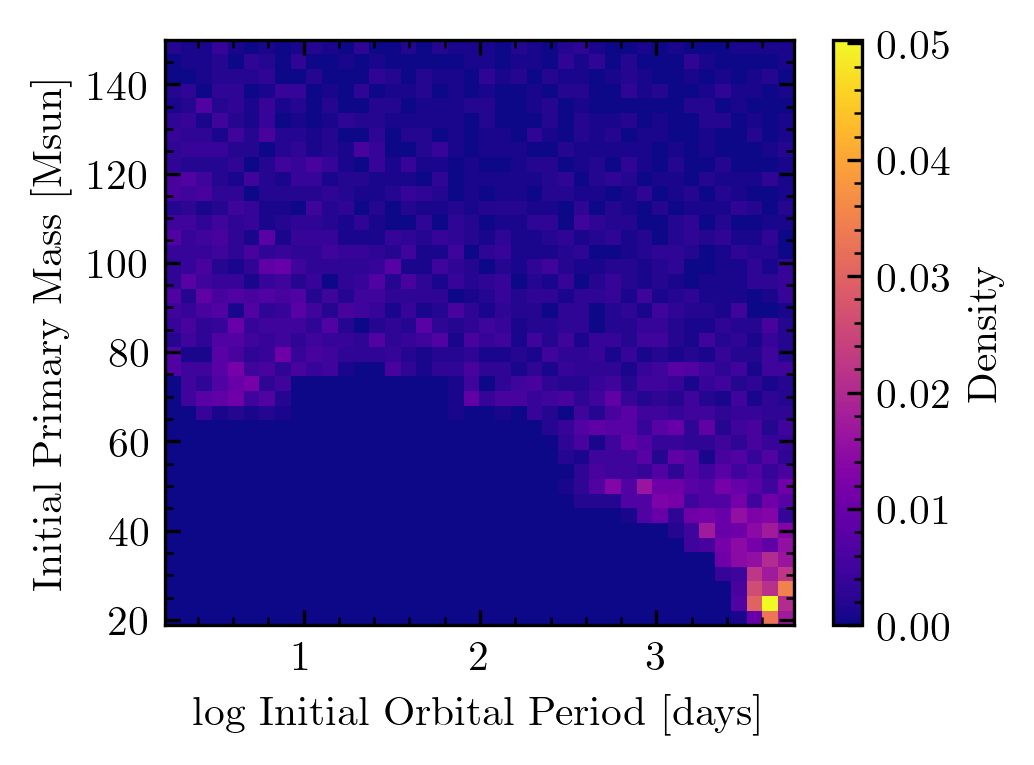

In [129]:
# initial mass distribution of non-interacting WR binaries
#mask_no_MT = S1_entries & np.isin(key_array, np.array(list(S1_no_MT_indices)))
mask_no_MT

no_MT_keys = np.unique(key_array[mask_no_MT])
initial_mass = pop.oneline['S1_mass_i'].loc[no_MT_keys]
initial_P = pop.oneline['orbital_period_i'].loc[no_MT_keys]
#plt.hist(initial_mass, bins=30, weights=np.ones_like(initial_mass)/len(initial_mass))
#plt.show()
#plt.hist(np.log10(initial_P), bins=30, weights=np.ones_like(initial_P)/len(initial_P))
#plt.show()

plt.hist2d(np.log10(initial_P.values.flatten()), initial_mass.values.flatten(),
           bins=(40, 40),
           cmap='plasma', density=True, range=[[np.log10(np.min(initial_P)), np.log10(np.max(initial_P))],
                                              [np.min(initial_mass), np.max(initial_mass)]])
plt.colorbar(label='Density')
plt.xlabel('log Initial Orbital Period [days]')
plt.ylabel('Initial Primary Mass [Msun]')

In [133]:
noMT = pop.oneline[no_MT_keys]
noMT_hist = pop.history[no_MT_keys]

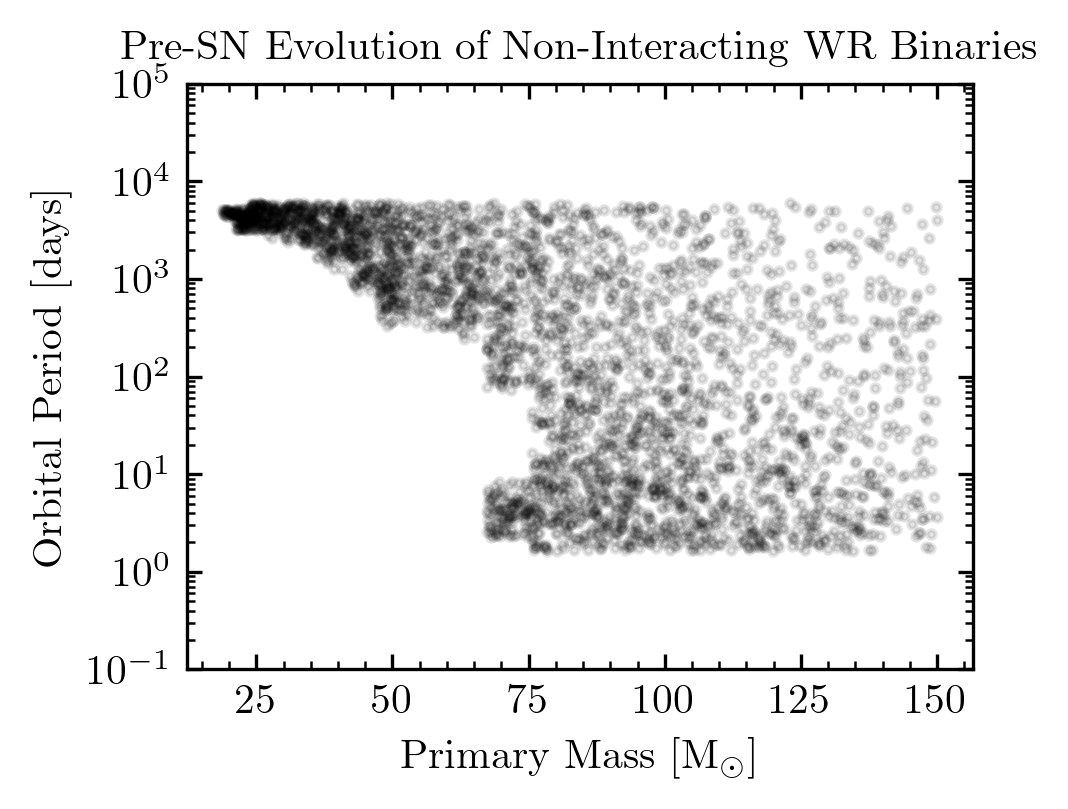

In [ ]:

for i in no_MT_keys:
    # select preSN evolution - filter until first SN
    hist = noMT_hist.loc[i]
    
    # Find first SN event (when either star becomes BH or NS)
    sn_mask = (hist['S1_state'] == 'BH') | (hist['S1_state'] == 'NS') | \
              (hist['S2_state'] == 'BH') | (hist['S2_state'] == 'NS')
    
    if sn_mask.any():
        # Get index of first SN
        first_sn_idx = hist[sn_mask].index[0]
        # Filter to before first SN
        hist_preSN = hist.loc[:first_sn_idx]
    else:
        # No SN occurred, use full history
        hist_preSN = hist
    
    plt.plot(hist_preSN['S1_mass'].iloc[0], hist_preSN['orbital_period'].iloc[0], 'black',marker='.', alpha=0.1)
    
plt.ylim(0.1, 1e5)
plt.yscale('log')
plt.xlabel('Primary Mass [M$_\\odot$]')
plt.ylabel('Orbital Period [days]')
plt.title('Pre-SN Evolution of Non-Interacting WR Binaries')
plt.show()

# most up there due to IMF. But still some widening due to wind mass loss.

# Where does the lower peak come from?
# Look at initial periods of non-interacting systems
# The tightest systems are weight most, because of the initial period distribution?
# So these get more weight, which leads to the lower period peak. 
# There's an interplay of IMF space and non-interacting. 
# At the shortest periods, the 

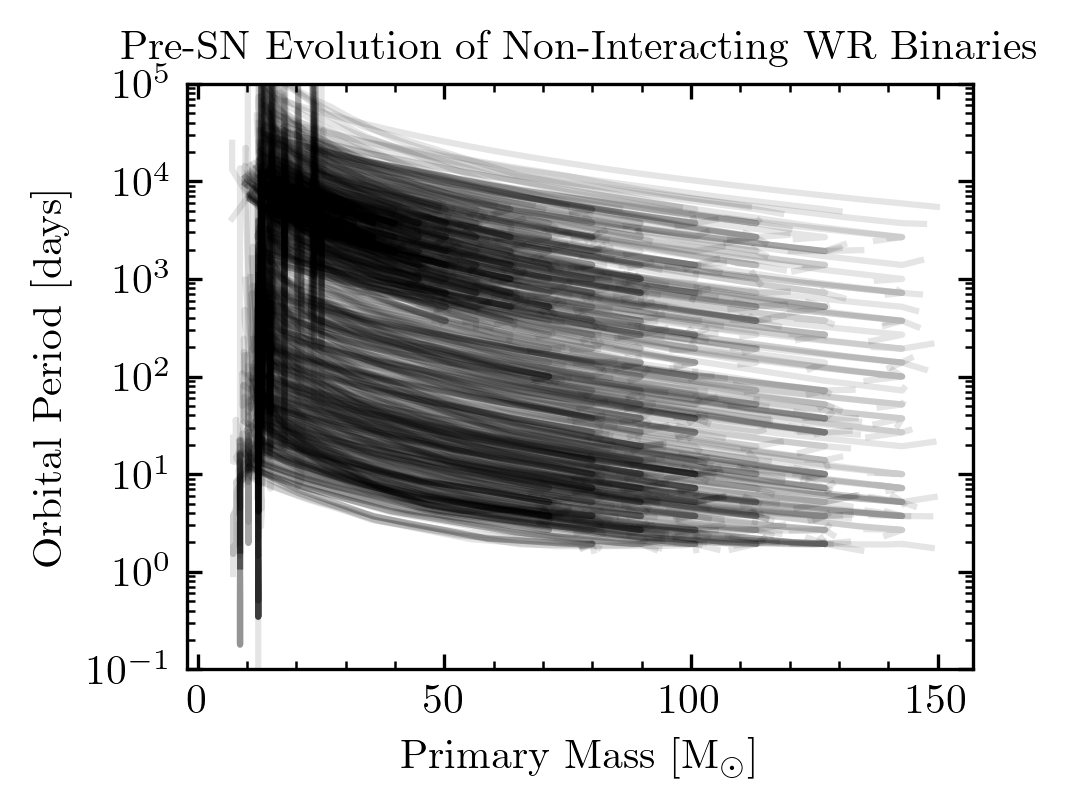

In [197]:
for i in no_MT_keys[:1000]:
    # select preSN evolution - filter until first SN
    hist = noMT_hist.loc[i]
    
    # Find first SN event (when either star becomes BH or NS)
    sn_mask = (hist['event'] == 'CC1')
    
    if sn_mask.any():
        # Get index of first SN
        first_sn_idx = hist[sn_mask].index[0]
        # Filter to before first SN
        hist_preSN = hist.loc[:first_sn_idx]
    else:
        # No SN occurred, use full history
        hist_preSN = hist
    
    plt.plot(hist_preSN['S1_mass'], hist_preSN['orbital_period'], 'black', alpha=0.1)
    
plt.ylim(0.1, 1e5)
plt.yscale('log')
plt.xlabel('Primary Mass [M$_\\odot$]')
plt.ylabel('Orbital Period [days]')
plt.title('Pre-SN Evolution of Non-Interacting WR Binaries')
plt.show()